# Frozen vs end-to-end encoders

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/comparisons/frozen_vs_end_to_end.ipynb)

Should a world model reuse a large pre-trained encoder, or learn a small one from its own data? Four encoders, each under an action-conditioned predictor, on PLDM's Two-Rooms:

| encoder | pre-trained on | during world-model training |
|---|---|---|
| DINOv2 ViT-S/14 | web images | frozen (DINO-WM) |
| V-JEPA 2.1 ViT-B | web video | frozen (DINO-WM predictor) |
| LeJEPA ViT | these frames, first | frozen (LeWM predictor) |
| LeWM ViT | nothing | trained end to end |

We compare success, training time and how many parameters each run trains.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]" timm einops

In [2]:
import time

import torch
from torch import nn
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import DINOWM, LeJEPA, LeWM
from torch_world.nn import MLP, CLSEncoder, PatchTokens, VideoTokens
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data
A point wanders through two rooms joined by a door, keeping its previous action 80% of the time: 1024 episodes of 65 steps, no rewards, no expert. Every model trains on the same episodes, cut into windows of the length its recipe uses.

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))


def loader(window):
    return DataLoader(TrajectoryDataset(data, window=window), batch_size=128, shuffle=True, drop_last=True)

## Pre-train LeJEPA on the frames
LeJEPA learns an encoder from single frames, with no actions: four color-jittered views of a frame should embed alike, and SIGReg keeps the embeddings Gaussian. The jitter changes colors only, so the position stays visible.

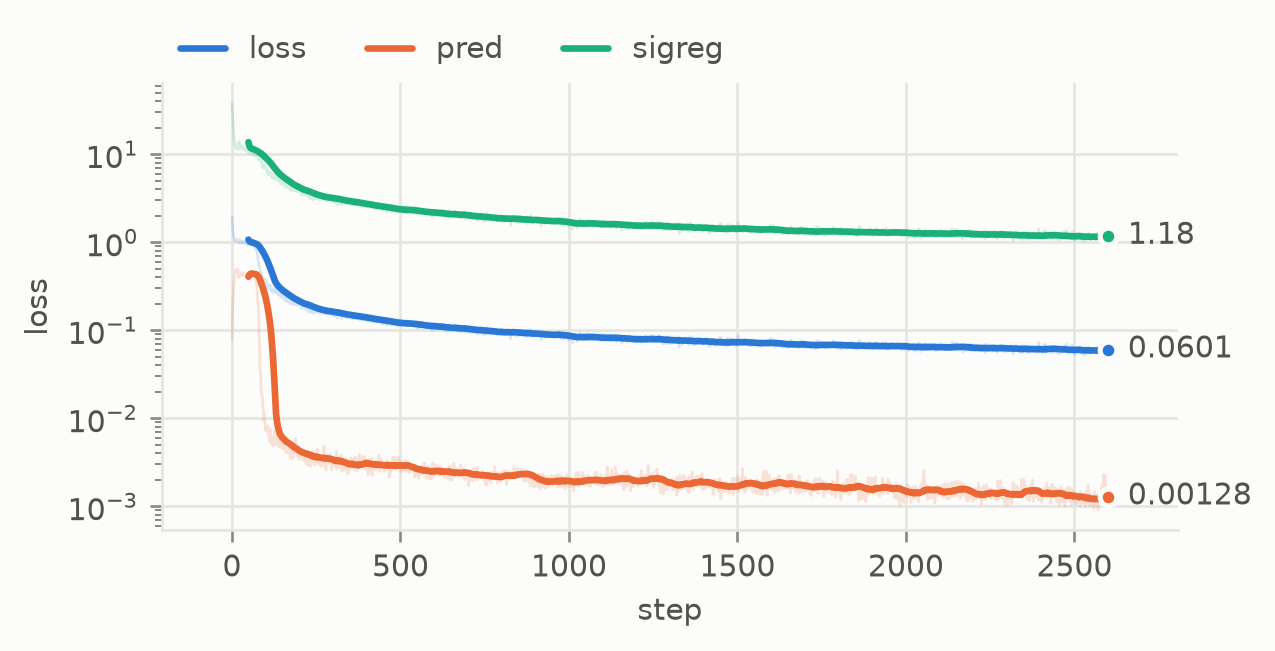

In [4]:
def vit():
    return CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)


def views(batch):
    frames = batch["pixels"][:, 0]
    return ((frames[:, None] * (0.7 + 0.6 * torch.rand(len(frames), 4, 3, 1, 1, device=device))).clamp(0, 1),)


tic = time.time()
lejepa = LeJEPA(vit(), MLP([128, 512, 128], norm=nn.BatchNorm1d)).to(device)
lejepa_log = fit(lejepa, loader(1), epochs=5, inputs=views)
pretrain_minutes = (time.time() - tic) / 60
plots.curves(lejepa_log, smooth=50)

## Four world models
The frozen web encoders feed DINO-WM's patch predictor; the frozen LeJEPA encoder and the end-to-end one feed LeWM's.

/clusterhome/kleyton/pytorch-world-roadmap-20261022/pydeps/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


DINOv2, frozen         7.5 min    2.45M of  24.51M parameters trained


/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


V-JEPA 2.1, frozen    23.2 min    4.84M of  91.67M parameters trained


LeJEPA, frozen         4.5 min    1.52M of   2.34M parameters trained


LeWM, end to end       6.4 min    2.34M of   2.34M parameters trained
(LeJEPA pre-training: 6.6 min more)


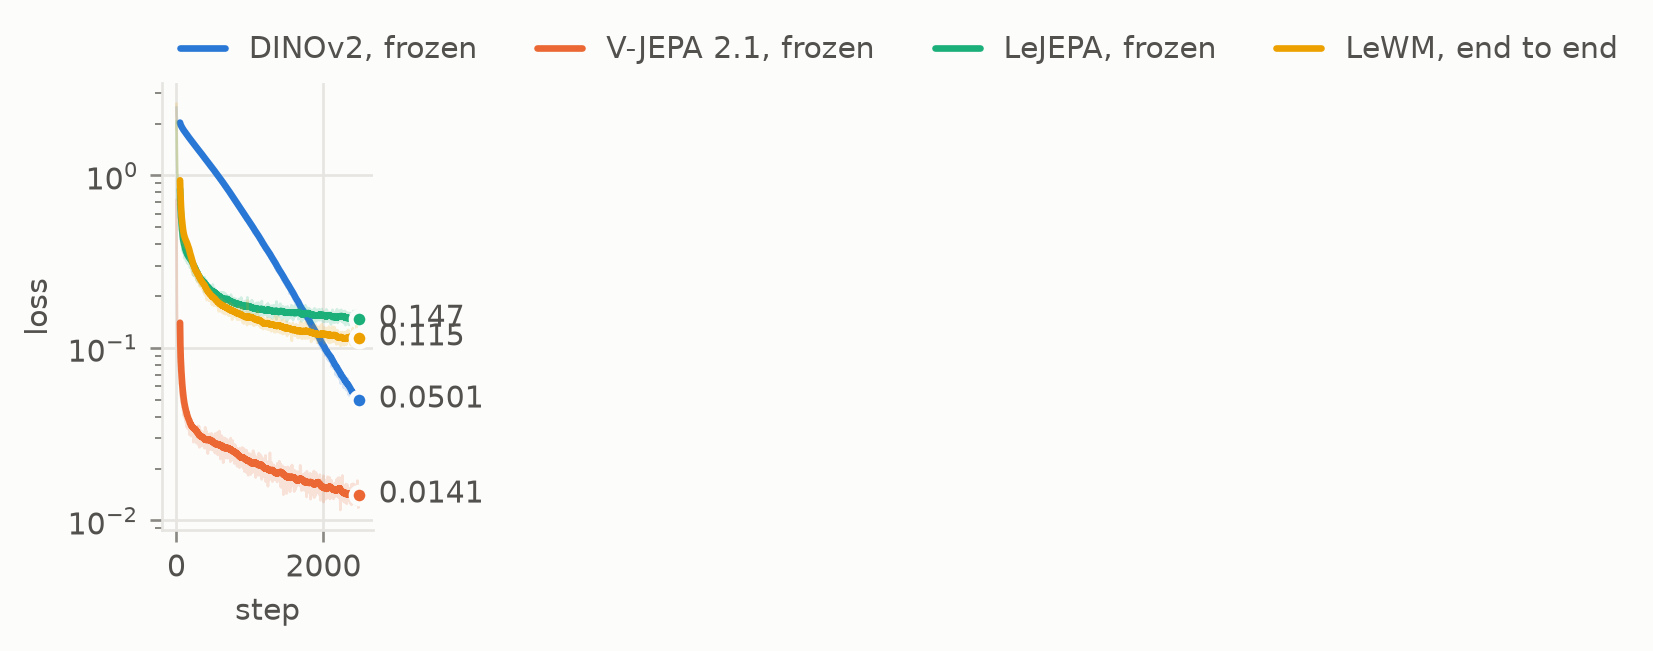

In [5]:
predictor = dict(depth=4, num_heads=4, head_dim=32, mlp_dim=512)
models = {
    "DINOv2, frozen": DINOWM(PatchTokens.from_hub("dinov2_vits14", size=56), num_patches=16, embed_dim=384, action_dim=2, **predictor),
    "V-JEPA 2.1, frozen": DINOWM(VideoTokens.from_hub("vjepa2_1_vit_base_384", size=64), num_patches=16, embed_dim=768, action_dim=2, **predictor),
    "LeJEPA, frozen": LeWM(lejepa.encoder.requires_grad_(False), action_dim=2, embed_dim=128, proj_dim=512, lamb=0.05, **predictor),
    "LeWM, end to end": LeWM(vit(), action_dim=2, embed_dim=128, proj_dim=512, lamb=0.05, **predictor),
}
logs, cost = {}, {}
for name, model in models.items():
    tic = time.time()
    logs[name] = fit(model.to(device), loader(4), epochs=5)["loss"]
    trained = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    total = sum(p.numel() for p in model.parameters()) / 1e6
    cost[name] = dict(minutes=(time.time() - tic) / 60, trained=trained, total=total)
    print(f"{name:20s} {cost[name]['minutes']:5.1f} min   {trained:5.2f}M of {total:6.2f}M parameters trained")
print(f"(LeJEPA pre-training: {pretrain_minutes:.1f} min more)")
plots.curves(logs, smooth=50)

## Evaluate
32 tasks with the goal in the same room (short) and 32 with the goal in the other room (long: through the door), 60 steps each. An episode succeeds when it comes within 0.1 of the goal at any step, as in LeWM's and PLDM's protocols; the interval is the 95% Wilson interval.

In [6]:
planner = CEM(horizon=8, action_dim=2, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
env = TwoRooms(batch_size=32, device=device)
results = {}
for task, same_room in [("same room", True), ("other room", False)]:
    start, goal = env.tasks(torch.Generator().manual_seed(1), same_room=same_room)
    policies = {name: evaluation.goal_policy(model, planner, env.render(goal)) for name, model in models.items()}
    results[task] = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
    print(f"== {task}\n{results[task]}")

/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


== same room
                              success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DINOv2, frozen         91% [76%, 97%]      91%    3.28          0.0368     0.855   0.184       0.433   1.74e+04
V-JEPA 2.1, frozen     91% [76%, 97%]      91%    3.14          0.0316     0.875   0.202       0.528   2.94e+04
LeJEPA, frozen         91% [76%, 97%]      91%    2.52          0.0262     0.883   0.213       0.445   1.23e+03
LeWM, end to end       69% [51%, 82%]      69%    1.95          0.0189     0.876   0.151       0.389   1.23e+03


== other room
                              success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DINOv2, frozen         25% [13%, 42%]      25%    4.88           0.595    0.0513  0.0753       0.365   1.73e+04
V-JEPA 2.1, frozen     56% [39%, 72%]      56%       8          0.0731     0.859   0.205       0.618   2.94e+04
LeJEPA, frozen         22% [11%, 39%]      22%    3.86           0.587    0.0356  0.0872       0.438   1.23e+03
LeWM, end to end       38% [23%, 55%]      38%    5.08           0.532   -0.0116   0.139       0.338   1.23e+03


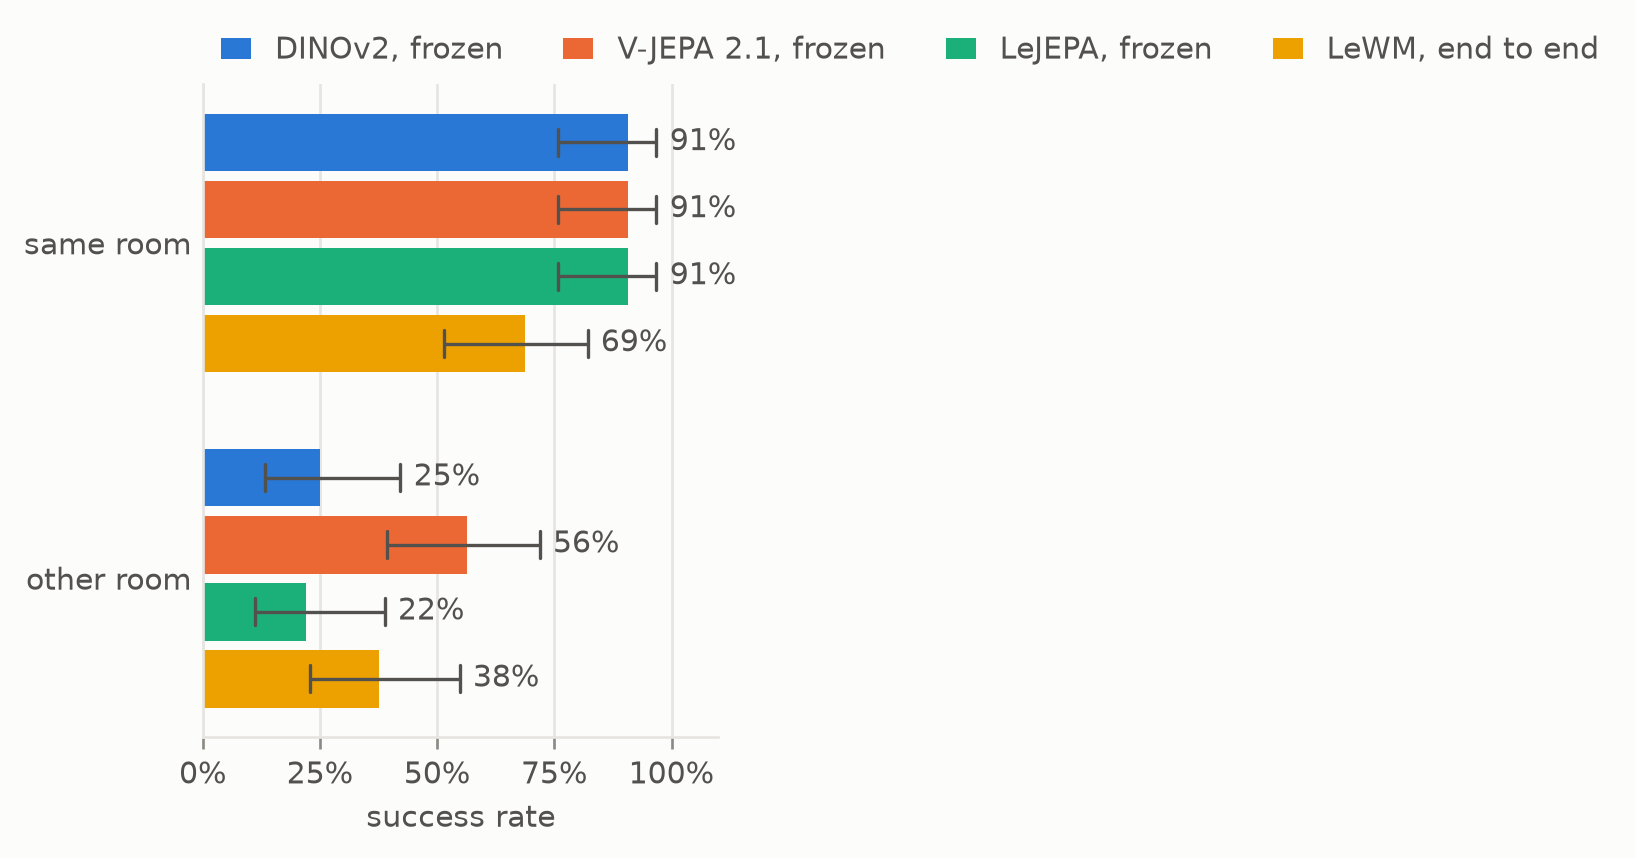

In [7]:
plots.bars({task: r.intervals() for task, r in results.items()}, xlabel="success rate")

## Summary
Web-scale encoders cost nothing to train here but are large to run, and see the scene at their own resolution and statistics; an encoder learned on the task is small and sees exactly what matters. The bars and the table above show which wins on this task, at this scale.